# Klasifikasi Arti Tangisan Bayi dengan CNN Log-Mel

In [1]:
import copy, hashlib, urllib.request, zipfile
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, soundfile as sf, onnxruntime as ort
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)
from cry_utils import CLASSES, ID, SR, CLIP, inventory, split, load_wave, mfcc, dtw_dist, CryCNN

torch.manual_seed(42); np.random.seed(42); torch.set_num_threads(8)
for d in ["models", "figures", "docs"]:
    Path(d).mkdir(exist_ok=True)

## 1. Data dan audit duplikat
Dataset Kaggle *Baby Crying Sounds* (mennaahmed23) diunduh lalu diperiksa: setiap file dibaca dan sidik jari (MD5) sinyalnya dibandingkan antar folder.

In [2]:
ROOT = Path("data/Baby Crying Sounds")
URL = "https://www.kaggle.com/api/v1/datasets/download/mennaahmed23/baby-crying-sounds-dataset"
if not ROOT.exists():
    zipfile.ZipFile(urllib.request.urlretrieve(URL, "data/baby_cry.zip")[0]).extractall("data")

raw = []
for p in sorted(ROOT.rglob("*.*")):
    x, sr = sf.read(p, dtype="float32", always_2d=True)
    raw.append(dict(folder=p.parent.name, name=p.name, sr=sr, md5=hashlib.md5(x.tobytes()).hexdigest()))
raw = pd.DataFrame(raw)
raw["salinan_lintas_folder"] = raw.groupby("md5").folder.transform("nunique") > 1
raw["pola_c_8k"] = raw.name.str.match(r"^\d+c\.wav$") & (raw.sr == 8000)
print("total file:", len(raw))
pd.crosstab(raw.folder, [raw.pola_c_8k, raw.salinan_lintas_folder], margins=True)

total file: 1313


pola_c_8k             False       True        All
salinan_lintas_folder False True False True      
folder                                           
belly pain               42   15     1   66   124
burping                  28    7     0   73   108
cold_hot                  8    0     0  100   108
discomfort                5   22     5  103   135
hungry                    1  381     0    0   382
laugh                   108    0     0    0   108
noise                   108    0     0    0   108
silence                 108    0     0    0   108
tired                     5   19     5  103   132
All                     413  444    11  445  1313

Contoh: file `<n>c.wav` 8 kHz di folder lain ternyata identik dengan rekaman *hungry*, jadi labelnya tidak bisa dipercaya.

In [3]:
ex = raw[raw.salinan_lintas_folder].groupby("md5").filter(lambda g: g.pola_c_8k.any()).sort_values("md5")
ex[["folder", "name", "sr", "md5"]].head(8)

,folder,name,sr,md5
736,hungry,aaa57dbd-7b88-454a-963e-6faa2f4ed4e7-143716651...,8000,00439749d700f6ad783cd1b340a50b51
97,belly pain,454c.wav,8000,00439749d700f6ad783cd1b340a50b51
86,belly pain,443c.wav,8000,0087a81250c9ac70d11b2f59bf85ceeb
725,hungry,a40b9b8d-e4bc-457a-badf-f38bdbc0c358-143001677...,8000,0087a81250c9ac70d11b2f59bf85ceeb
495,hungry,10A40438-09AA-4A21-83B4-8119F03F7A11-143084803...,8000,00a049f072c98d3d3d50a9990fd69611
274,cold_hot,33c.wav,8000,00a049f072c98d3d3d50a9990fd69611
38,belly pain,395c.wav,8000,00a7e23f59cbb7372c90d6abf9a8a94d
851,hungry,FAE74A94-9968-43ED-958C-50D7C4C1F13C-143077087...,8000,00a7e23f59cbb7372c90d6abf9a8a94d


Setelah file salinan dibuang, label rekaman asli donateacry diambil dari akhiran nama file, dan tiap file diberi grup (bayi atau blok potongan rekaman) untuk pembagian data.

In [4]:
df = inventory(ROOT)
df["split"] = split(df)
df["y"] = df.label.map(CLASSES.index)
print(f"file bersih: {len(df)} dari {len(raw)} | grup: {df.group.nunique()}")
pd.crosstab(df.label, df.split, margins=True).loc[CLASSES + ["All"], ["train", "val", "test", "All"]]

file bersih: 857 dari 1313 | grup: 386


split,train,val,test,All
label,,,,
hungry,248,57,77,382
belly_pain,37,9,11,57
burping,23,5,7,35
cold_hot,10,2,3,15
discomfort,17,1,2,20
tired,16,3,5,24
laugh,72,16,20,108
noise,70,16,22,108
silence,72,16,20,108


## 2. Eksplorasi singkat
Sebaran kelas per subset dan per sumber rekaman.

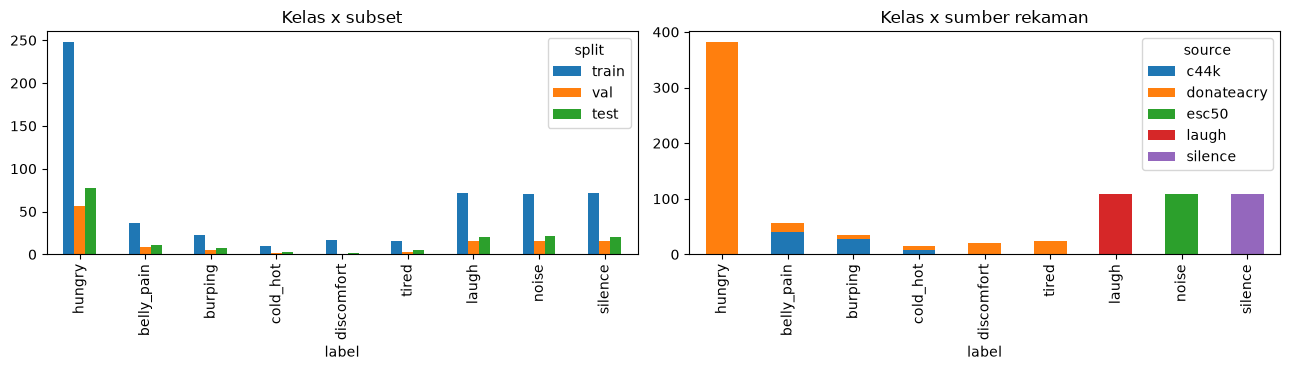

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
pd.crosstab(df.label, df.split).loc[CLASSES, ["train", "val", "test"]].plot.bar(ax=ax[0], title="Kelas x subset")
pd.crosstab(df.label, df.source).loc[CLASSES].plot.bar(ax=ax[1], stacked=True, title="Kelas x sumber rekaman")
plt.tight_layout(); plt.savefig("figures/distribusi.png", dpi=150); plt.show()

Gelombang dan log-mel spektrogram satu contoh per kelas, dihitung dengan front-end yang sama dengan model.

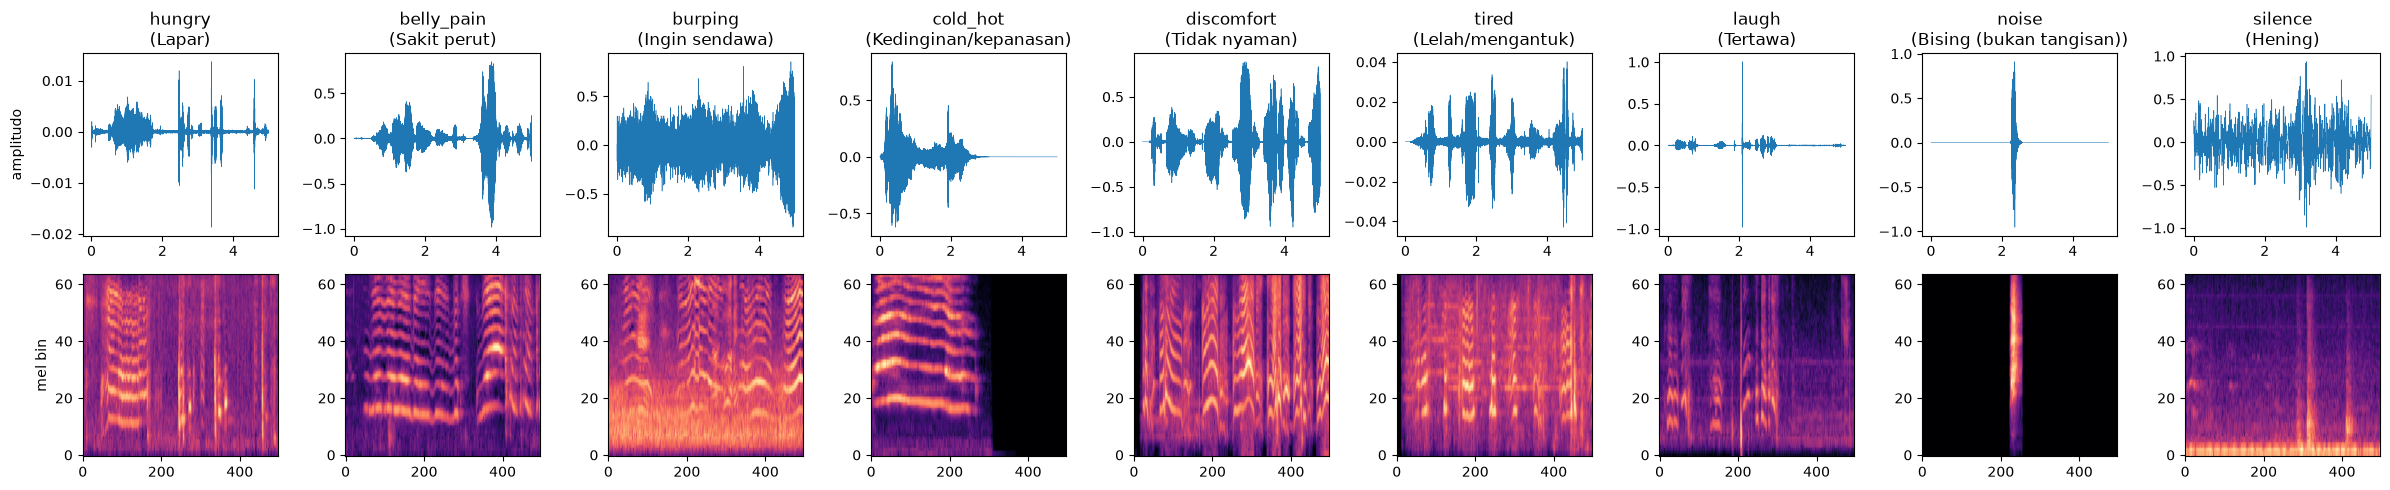

In [6]:
fe = CryCNN().eval()
ex = df[df.split == "train"].groupby("label").head(1).set_index("label").loc[CLASSES]
fig, ax = plt.subplots(2, 9, figsize=(24, 5))
for i, (lab, r) in enumerate(ex.iterrows()):
    w = load_wave(r.path)[:CLIP]
    ax[0, i].plot(np.arange(len(w)) / SR, w, lw=.4); ax[0, i].set_title(f"{lab}\n({ID[lab]})")
    with torch.no_grad():
        ax[1, i].imshow(fe.logmel(torch.from_numpy(w)[None])[0], origin="lower", aspect="auto", cmap="magma")
ax[0, 0].set_ylabel("amplitudo"); ax[1, 0].set_ylabel("mel bin")
plt.tight_layout(); plt.savefig("figures/contoh_mel.png", dpi=150); plt.show()

## 3. Praproses
Semua file diubah ke mono 8 kHz (ukuran asli donateacry) dan disimpan di memori.

In [7]:
waves = [load_wave(p) for p in df.path]
idx = {s: np.flatnonzero(df.split == s) for s in ["train", "val", "test"]}
y = df.y.values
print({s: len(i) for s, i in idx.items()}, "| durasi (dtk):", df.dur.describe()[["min", "50%", "max"]].round(2).to_dict())

{'train': 565, 'val': 125, 'test': 167} | durasi (dtk): {'min': 4.96, '50%': 6.66, 'max': 7.06}


## 4. Baseline DTW (template matching)
Tiap klip menjadi deret MFCC 20 koefisien; klip uji diberi label template latih dengan jarak DTW terkecil (1-NN).

In [8]:
M = torch.from_numpy(np.stack([mfcc(w) for w in waves]))
q = np.concatenate([idx["val"], idx["test"]])
Dq = dtw_dist(M[q], M[idx["train"]])
nn_pred = y[idx["train"]][Dq.argmin(1).numpy()]
dtw_pred = {"val": nn_pred[:len(idx["val"])], "test": nn_pred[len(idx["val"]):]}

def scores(yt, yp):
    return dict(akurasi=accuracy_score(yt, yp), balanced_acc=balanced_accuracy_score(yt, yp),
                macro_f1=f1_score(yt, yp, average="macro", labels=range(len(CLASSES)), zero_division=0))

pd.DataFrame({s: scores(y[idx[s]], dtw_pred[s]) for s in ["val", "test"]}).T.round(3)

,akurasi,balanced_acc,macro_f1
val,0.416,0.425,0.398
test,0.395,0.417,0.398


## 5. Model CNN
Front-end log-mel (STFT sebagai konvolusi, 64 mel) di dalam model, normalisasi rata-rata per pita (CMVN), lalu empat blok konvolusi 3x3 dan global average pooling.

In [9]:
model = CryCNN()
print(model)
print(f"parameter dilatih: {sum(p.numel() for p in model.parameters()):,}")

CryCNN(
  (augment): Sequential(
    (0): FrequencyMasking()
    (1): TimeMasking()
  )
  (cnn): Sequential(
    (0): BatchNorm2d(1, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): ReLU()
    (12): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (13):

## 6. Pelatihan
AdamW (lr 3e-4), cross-entropy berbobot akar invers frekuensi kelas, potongan acak 5 detik + derau SNR 20-40 dB, maksimal 100 epoch, early stopping patience 15 pada val loss.

In [10]:
EPOCHS, PATIENCE, BS = 100, 15, 32
counts = np.bincount(y[idx["train"]], minlength=len(CLASSES))
crit = nn.CrossEntropyLoss(weight=torch.tensor((len(idx["train"]) / (len(CLASSES) * counts)) ** 0.5, dtype=torch.float32))
opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-3)
rng = np.random.default_rng(42)

def batch(ids):
    xs = []
    for i in ids:
        w = waves[i]; s = rng.integers(0, len(w) - CLIP + 1)
        x = w[s:s + CLIP]
        snr = rng.uniform(20, 40)
        xs.append(x + rng.standard_normal(CLIP).astype(np.float32) * np.sqrt((x ** 2).mean() / 10 ** (snr / 10)))
    return torch.from_numpy(np.stack(xs)), torch.from_numpy(y[ids])

@torch.no_grad()
def evaluate(m, ids):
    m.eval()
    logits = torch.cat([m(torch.from_numpy(waves[i])[None]) for i in ids])  # klip utuh, sama seperti di website
    yt = torch.from_numpy(y[ids])
    return crit(logits, yt).item(), (logits.argmax(1) == yt).float().mean().item(), logits

hist, best, best_loss, wait = [], None, float("inf"), 0
for ep in range(1, EPOCHS + 1):
    model.train()
    for b in np.array_split(rng.permutation(idx["train"]), int(np.ceil(len(idx["train"]) / BS))):
        xb, yb = batch(b)
        opt.zero_grad(); loss = crit(model(xb), yb); loss.backward(); opt.step()
    tl, ta, _ = evaluate(model, idx["train"])
    vl, va, vlog = evaluate(model, idx["val"])
    vf = f1_score(y[idx["val"]], vlog.argmax(1), average="macro")
    hist.append(dict(epoch=ep, train_loss=tl, train_acc=ta, val_loss=vl, val_acc=va, val_f1=vf))
    if vl < best_loss:
        best_loss, best, wait = vl, copy.deepcopy(model.state_dict()), 0
    else:
        wait += 1
    if ep % 5 == 0 or wait == 0:
        print(f"epoch {ep:2d} | train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f} F1 {vf:.3f}" + (" *" if wait == 0 else ""))
    if wait >= PATIENCE:
        print("early stopping di epoch", ep); break
model.load_state_dict(best); model.eval()
hist = pd.DataFrame(hist)

epoch  1 | train loss 1.916 acc 0.258 | val loss 1.910 acc 0.264 F1 0.149 *


epoch  2 | train loss 1.648 acc 0.589 | val loss 1.625 acc 0.584 F1 0.259 *


epoch  3 | train loss 1.586 acc 0.591 | val loss 1.511 acc 0.640 F1 0.297 *


epoch  4 | train loss 1.513 acc 0.612 | val loss 1.420 acc 0.648 F1 0.336 *


epoch  5 | train loss 1.447 acc 0.658 | val loss 1.356 acc 0.712 F1 0.425 *


epoch  7 | train loss 1.385 acc 0.658 | val loss 1.305 acc 0.664 F1 0.379 *


... (23 outputs left out)

epoch 60 | train loss 0.812 acc 0.816 | val loss 0.902 acc 0.880 F1 0.621


epoch 65 | train loss 1.272 acc 0.483 | val loss 1.305 acc 0.504 F1 0.426


epoch 70 | train loss 0.838 acc 0.788 | val loss 0.921 acc 0.840 F1 0.607


early stopping di epoch 74


## 7. Kurva belajar
Kurva train dan val (keduanya dievaluasi pada klip bersih) untuk memeriksa overfitting; garis putus-putus menandai epoch terbaik.

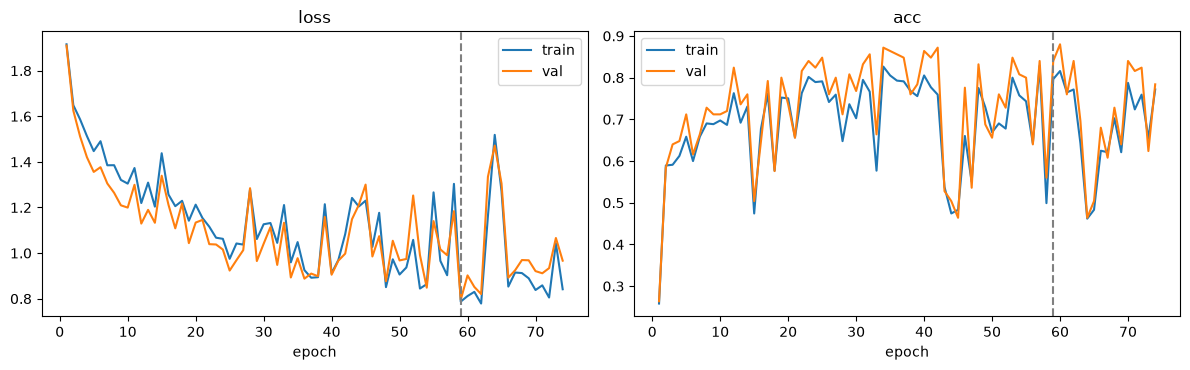

epoch terbaik 59 dari 74: train acc 0.796, val acc 0.840, selisih -0.044 | train loss 0.787, val loss 0.795


In [11]:
b = hist.loc[hist.val_loss.idxmin()]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for k, a in zip(["loss", "acc"], ax):
    a.plot(hist.epoch, hist[f"train_{k}"], label="train"); a.plot(hist.epoch, hist[f"val_{k}"], label="val")
    a.axvline(b.epoch, ls="--", c="gray"); a.set_xlabel("epoch"); a.set_title(k); a.legend()
plt.tight_layout(); plt.savefig("figures/kurva_belajar.png", dpi=150); plt.show()
print(f"epoch terbaik {int(b.epoch)} dari {len(hist)}: train acc {b.train_acc:.3f}, val acc {b.val_acc:.3f}, "
      f"selisih {b.train_acc - b.val_acc:.3f} | train loss {b.train_loss:.3f}, val loss {b.val_loss:.3f}")

## 8. Evaluasi pada data uji
Data uji baru dipakai di sini, sekali, setelah model final dipilih dengan data validasi.

              precision    recall  f1-score   support

      hungry      0.913     0.818     0.863        77
  belly_pain      0.367     1.000     0.537        11
     burping      0.857     0.857     0.857         7
    cold_hot      0.000     0.000     0.000         3
  discomfort      0.000     0.000     0.000         2
       tired      0.000     0.000     0.000         5
       laugh      0.741     1.000     0.851        20
       noise      0.833     0.455     0.588        22
     silence      1.000     1.000     1.000        20

    accuracy                          0.778       167
   macro avg      0.523     0.570     0.522       167
weighted avg      0.799     0.778     0.768       167



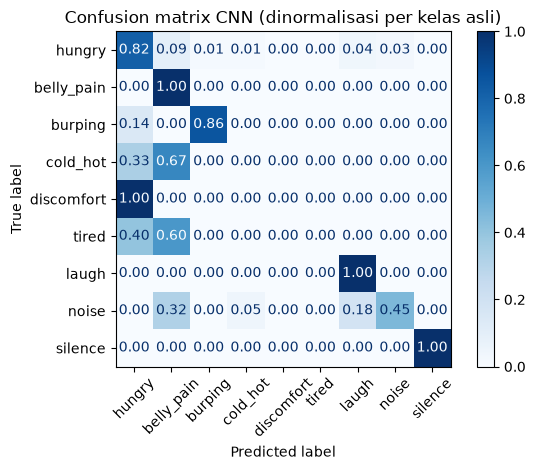

In [12]:
_, _, logits = evaluate(model, idx["test"])
cnn_pred = logits.argmax(1).numpy()
print(classification_report(y[idx["test"]], cnn_pred, labels=range(len(CLASSES)), target_names=CLASSES, digits=3, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y[idx["test"]], cnn_pred, labels=range(len(CLASSES)), display_labels=CLASSES,
                                        normalize="true", values_format=".2f", cmap="Blues", xticks_rotation=45)
plt.title("Confusion matrix CNN (dinormalisasi per kelas asli)"); plt.tight_layout()
plt.savefig("figures/confusion_matrix.png", dpi=150); plt.show()

Perbandingan DTW 1-NN dan CNN pada data uji yang sama.

In [13]:
_, _, vlog = evaluate(model, idx["val"])
cmp = pd.DataFrame({("DTW 1-NN", s): scores(y[idx[s]], dtw_pred[s]) for s in ["val", "test"]} |
                   {("CNN log-mel", "val"): scores(y[idx["val"]], vlog.argmax(1).numpy()),
                    ("CNN log-mel", "test"): scores(y[idx["test"]], cnn_pred)}).T.round(3)
cmp.to_csv("models/perbandingan.csv"); cmp

akurasi  balanced_acc  macro_f1
DTW 1-NN    val     0.416         0.425     0.398
            test    0.395         0.417     0.398
CNN log-mel val     0.840         0.619     0.579
            test    0.778         0.570     0.522

Recall per kelas pada data uji untuk kedua metode.

In [14]:
rec = lambda p: pd.Series([(p[y[idx["test"]] == k] == k).mean() for k in range(len(CLASSES))], index=CLASSES)
pd.DataFrame({"n_uji": np.bincount(y[idx["test"]], minlength=len(CLASSES)),
              "DTW": rec(dtw_pred["test"]).values, "CNN": rec(cnn_pred).values}, index=CLASSES).round(3)

,n_uji,DTW,CNN
hungry,77,0.104,0.818
belly_pain,11,0.636,1.000
burping,7,0.857,0.857
cold_hot,3,0.000,0.000
discomfort,2,0.000,0.000
tired,5,0.000,0.000
laugh,20,0.600,1.000
noise,22,0.955,0.455
silence,20,0.600,1.000


## 9. Simpan model
Bobot PyTorch disimpan, lalu model diekspor ke ONNX dengan panjang input dinamis untuk website.

In [15]:
torch.save(model.state_dict(), "models/cry_cnn.pt")
hist.to_csv("models/history.csv", index=False)
torch.onnx.export(model, (torch.from_numpy(waves[idx["test"][0]])[None],), "docs/model.onnx",
                  input_names=["audio"], output_names=["logits"], dynamic_axes={"audio": {1: "n"}},
                  opset_version=17, dynamo=False)
sess = ort.InferenceSession("docs/model.onnx")
diff = max(np.abs(sess.run(None, {"audio": waves[i][None]})[0] - logits[[k]].numpy()).max()
           for k, i in enumerate(idx["test"]))
print(f"ONNX {Path('docs/model.onnx').stat().st_size / 1e6:.2f} MB | selisih maks logit PyTorch vs ONNX: {diff:.2e}")
assert diff < 1e-3

C:\Users\Asus\AppData\Local\Temp\ipykernel_30424\658671724.py:3: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter will be the default. To switch now, set dynamo=True in torch.onnx.export. This new exporter supports features like exporting LLMs with DynamicCache. We encourage you to try it and share feedback to help improve the experience. Learn more about the new export logic: https://pytorch.org/docs/stable/onnx_dynamo.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html.
  torch.onnx.export(model, (torch.from_numpy(waves[idx["test"][0]])[None],), "docs/model.onnx",


ONNX 0.70 MB | selisih maks logit PyTorch vs ONNX: 1.43e-05


## 10. Muat ulang dan uji coba
Model dimuat dari file, dicek sama dengan model di memori, lalu dicoba langsung dari file audio mentah.

In [16]:
loaded = CryCNN(); loaded.load_state_dict(torch.load("models/cry_cnn.pt")); loaded.eval()
with torch.no_grad():
    assert torch.allclose(loaded(torch.from_numpy(waves[idx["test"][0]])[None]), logits[[0]], atol=1e-5)

def predict(path):
    with torch.no_grad():
        p = loaded(torch.from_numpy(load_wave(path))[None]).softmax(1)[0]
    k = int(p.argmax())
    return CLASSES[k], ID[CLASSES[k]], round(float(p[k]), 3)

sample = df[df.split == "test"].groupby("label").head(2).sample(10, random_state=1)
trial = pd.DataFrame([(Path(r.path).name[-28:], r.label, *predict(r.path)) for r in sample.itertuples()],
                     columns=["file", "asli", "prediksi", "arti", "keyakinan"])
print("benar:", (trial.asli == trial.prediksi).sum(), "dari", len(trial)); trial

benar: 6 dari 10


,file,asli,prediksi,arti,keyakinan
0,B-1436462707-1.1-m-26-dc.wav,discomfort,hungry,Lapar,0.506
1,549c.wav,burping,burping,Ingin sendawa,0.816
2,1-32318-A.ogg,noise,belly_pain,Sakit perut,0.546
3,548c.wav,burping,burping,Ingin sendawa,0.736
4,silence.wav_0.wav,silence,silence,Hening,0.444
5,8-1430530218-1.0-m-26-dc.wav,discomfort,hungry,Lapar,0.496
6,silence.wav_1.wav,silence,silence,Hening,0.597
7,61c.ogg,cold_hot,belly_pain,Sakit perut,0.402
8,402c.wav,belly_pain,belly_pain,Sakit perut,0.879
9,laugh_1.m4a_0.wav,laugh,laugh,Tertawa,0.934
